# โครงงานวิเคราะห์ข้อมูลด้วย Python
## ชุดข้อมูล Advertising: ความสัมพันธ์ระหว่างงบโฆษณา (TV, Radio, Newspaper) กับยอดขาย (Sales)

**วิธีใช้:** วางไฟล์ `Advertising.csv` ไว้โฟลเดอร์เดียวกับไฟล์นี้ แล้วกด Run All
กราฟทุกภาพจะถูกบันทึกลงโฟลเดอร์ `output` อัตโนมัติ (ใช้ส่งงานสัปดาห์ที่ 3 ได้เลย)

## 1. นำเข้า library และอ่านข้อมูล

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# สร้างโฟลเดอร์เก็บรูปกราฟ
os.makedirs('output', exist_ok=True)

df = pd.read_csv('Advertising.csv')
df = df.drop(columns='Unnamed: 0')   # คอลัมน์นี้เป็นแค่เลขลำดับ ไม่ใช่ข้อมูล
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 2. ตั้งฟอนต์ภาษาไทยสำหรับกราฟ
ถ้าเครื่องไม่มี TH Sarabun New โปรแกรมจะลองฟอนต์ถัดไปในรายการให้เอง (Tahoma มากับ Windows และรองรับภาษาไทย)

In [ ]:
plt.rcParams['font.family'] = ['TH Sarabun New', 'Tahoma', 'Leelawadee UI', 'Noto Sans Thai', 'sans-serif']
plt.rcParams['font.size'] = 16
plt.rcParams['axes.unicode_minus'] = False   # แก้เครื่องหมายลบไม่ขึ้น

## 3. ตรวจสอบข้อมูลเบื้องต้น
ตอบ: ข้อมูลมีกี่แถว กี่คอลัมน์ ชนิดข้อมูลอะไร มีค่าสูญหายหรือแถวซ้ำหรือไม่

In [4]:
print('จำนวนแถว, คอลัมน์ =', df.shape)
print()
df.info()

จำนวนแถว, คอลัมน์ = (200, 4)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
print('ค่าสูญหายในแต่ละคอลัมน์')
print(df.isnull().sum())
print()
print('จำนวนแถวซ้ำ =', df.duplicated().sum())

ค่าสูญหายในแต่ละคอลัมน์
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

จำนวนแถวซ้ำ = 0


## 4. สถิติเชิงพรรณนา
ค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานแบบตัวอย่าง (หารด้วย n-1 จึงใส่ `ddof=1`)

In [6]:
summary = pd.DataFrame({
    'ค่าเฉลี่ย': df.mean(),
    'ส.บ.ม. (ddof=1)': df.std(ddof=1),
    'ต่ำสุด': df.min(),
    'มัธยฐาน': df.median(),
    'สูงสุด': df.max()
}).round(2)
summary

,ค่าเฉลี่ย,ส.บ.ม. (ddof=1),ต่ำสุด,มัธยฐาน,สูงสุด
TV,147.04,85.85,0.7,149.75,296.4
Radio,23.26,14.85,0.0,22.90,49.6
Newspaper,30.55,21.78,0.3,25.75,114.0
Sales,14.02,5.22,1.6,12.90,27.0


In [ ]:
# ดูสรุปทีเดียวด้วย describe() เพื่อเทียบผล
df.describe().round(2)

In [ ]:
# บันทึกตารางสรุปเป็นไฟล์ CSV สำหรับนำไปทำตารางในรายงาน (สัปดาห์ที่ 2)
summary.to_csv('output/ตารางสถิติ.csv', encoding='utf-8-sig')

## 5. ตรวจหาค่าผิดปกติด้วยกฎ 1.5 × IQR
ค่าที่ต่ำกว่า Q1 − 1.5×IQR หรือสูงกว่า Q3 + 1.5×IQR ถือเป็นค่าผิดปกติ

In [7]:
rows = []
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, n])

outlier_table = pd.DataFrame(rows, columns=['ตัวแปร', 'Q1', 'Q3', 'IQR', 'ขอบล่าง', 'ขอบบน', 'จำนวนค่าผิดปกติ']).round(2)
outlier_table

,ตัวแปร,Q1,Q3,IQR,ขอบล่าง,ขอบบน,จำนวนค่าผิดปกติ
0,TV,74.38,218.82,144.45,-142.30,435.50,0
1,Radio,9.98,36.52,26.55,-29.85,76.35,0
2,Newspaper,12.75,45.10,32.35,-35.78,93.62,2
3,Sales,10.38,17.40,7.02,-0.16,27.94,0


In [8]:
# ดูแถวที่เป็นค่าผิดปกติของ Newspaper
q1 = df['Newspaper'].quantile(0.25)
q3 = df['Newspaper'].quantile(0.75)
iqr = q3 - q1
df[(df['Newspaper'] < q1 - 1.5*iqr) | (df['Newspaper'] > q3 + 1.5*iqr)]

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


## 6. กราฟ

### 6.1 ฮิสโตแกรม (ดูรูปร่างการกระจายของแต่ละตัวแปร)

findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.


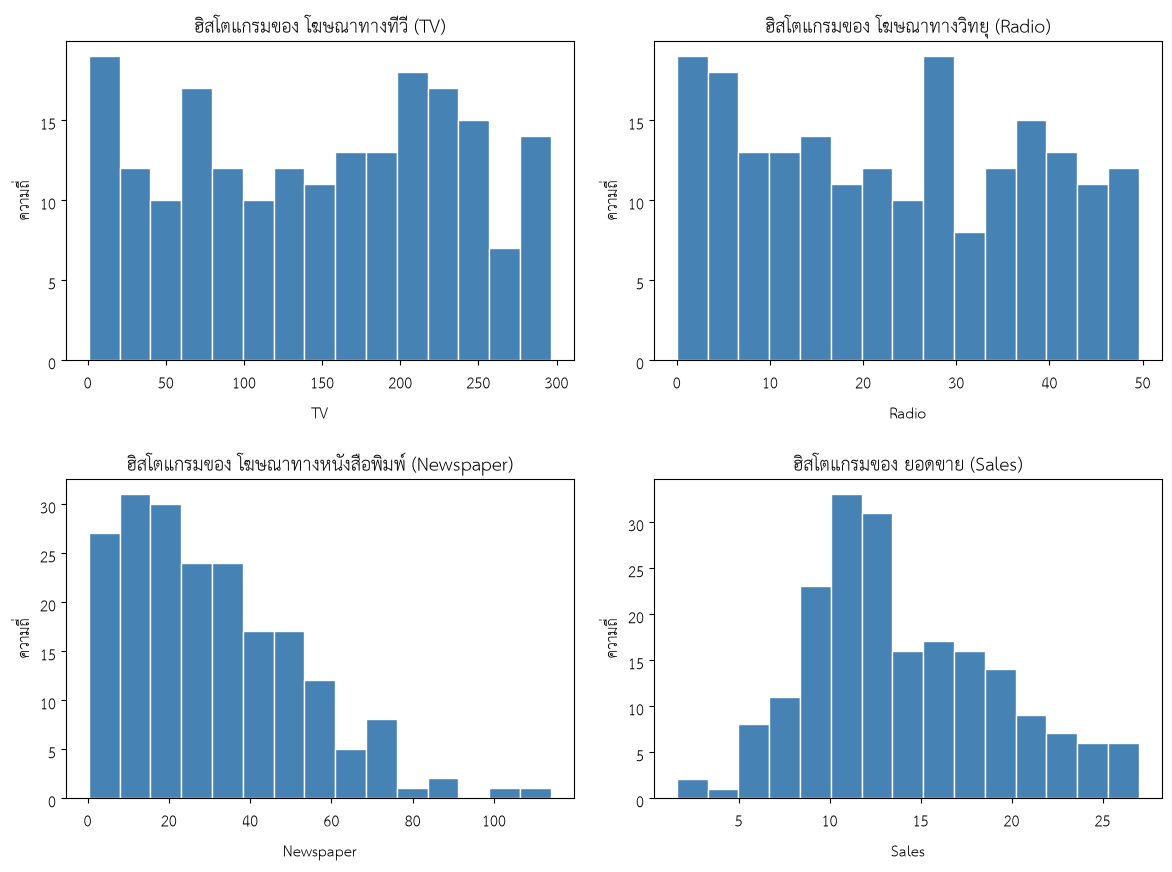

In [9]:
names = {'TV': 'โฆษณาทางทีวี (TV)', 'Radio': 'โฆษณาทางวิทยุ (Radio)',
         'Newspaper': 'โฆษณาทางหนังสือพิมพ์ (Newspaper)', 'Sales': 'ยอดขาย (Sales)'}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flatten(), df.columns):
    ax.hist(df[col], bins=15, color='steelblue', edgecolor='white')
    ax.set_title('ฮิสโตแกรมของ ' + names[col])
    ax.set_xlabel(col)
    ax.set_ylabel('ความถี่')
plt.tight_layout()
plt.savefig('output/histogram.png', dpi=200)
plt.show()

### 6.2 แผนภาพกล่อง (ดูการกระจายและค่าผิดปกติ)

findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.


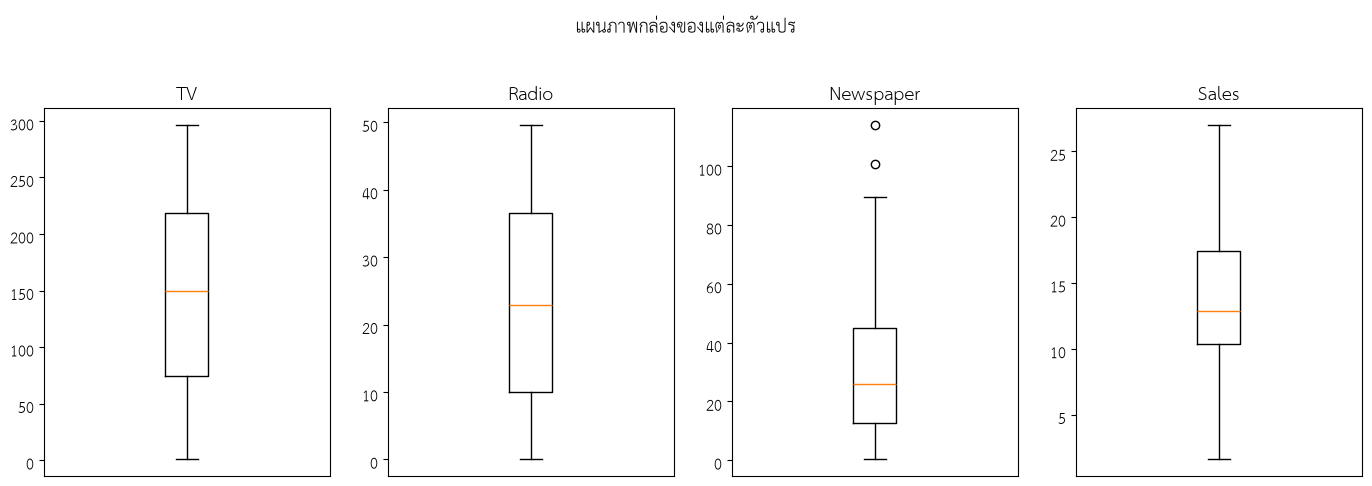

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, col in zip(axes, df.columns):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle('แผนภาพกล่องของแต่ละตัวแปร')
plt.tight_layout()
plt.savefig('output/boxplot.png', dpi=200)
plt.show()

### 6.3 กราฟการกระจาย (ดูความสัมพันธ์ระหว่างงบโฆษณาแต่ละช่องทางกับยอดขาย)

findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.
findfont: Font family 'Noto Sans Thai' not found.


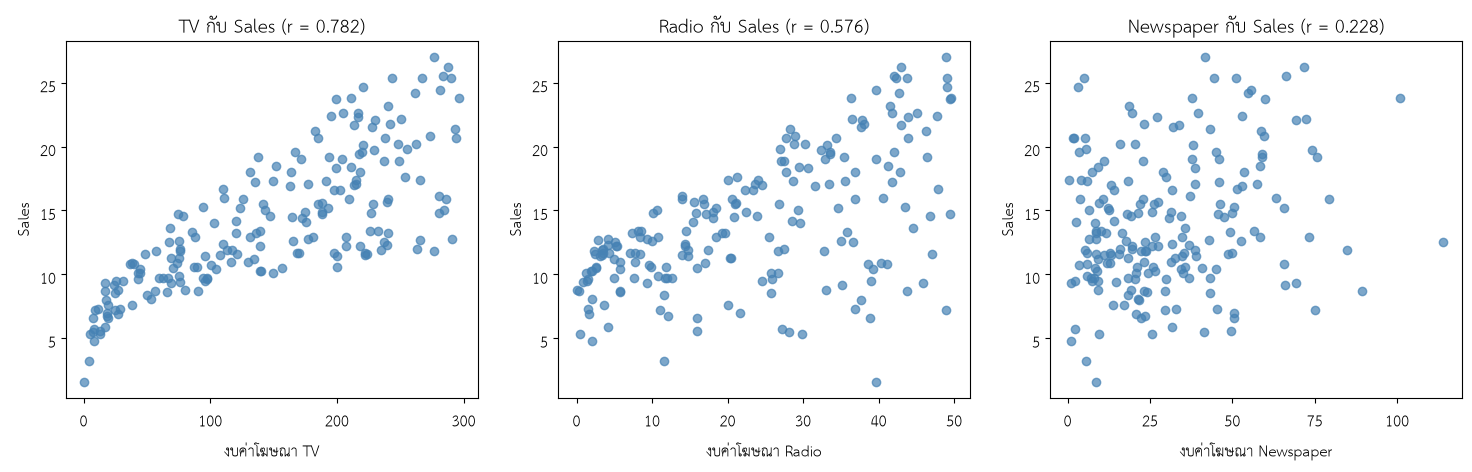

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    ax.scatter(df[col], df['Sales'], color='steelblue', alpha=0.7)
    r = df[col].corr(df['Sales'])
    ax.set_title(col + ' กับ Sales (r = ' + str(round(r, 3)) + ')')
    ax.set_xlabel('งบค่าโฆษณา ' + col)
    ax.set_ylabel('Sales')
plt.tight_layout()
plt.savefig('output/scatter.png', dpi=200)
plt.show()

## 7. ค่าสหสัมพันธ์

In [12]:
corr = df.corr().round(3)
corr

,TV,Radio,Newspaper,Sales
TV,1.000,0.055,0.057,0.782
Radio,0.055,1.000,0.354,0.576
Newspaper,0.057,0.354,1.000,0.228
Sales,0.782,0.576,0.228,1.000


In [13]:
# สหสัมพันธ์ของแต่ละช่องทางกับ Sales เรียงจากมากไปน้อย
print(corr['Sales'].drop('Sales').sort_values(ascending=False))
corr.to_csv('output/ตารางสหสัมพันธ์.csv', encoding='utf-8-sig')

TV           0.782
Radio        0.576
Newspaper    0.228
Name: Sales, dtype: float64


## 8. สรุปผลและตีความ (เขียนเองจากผลที่ได้ด้านบน)

**แนวทางตอบ** (เติมตัวเลขจริงจากผลรันของพวกคุณ)

1. **สถิติเชิงพรรณนา:** ตัวแปรใดมีค่าเฉลี่ยสูงสุด และตัวแปรใดกระจายตัวมากที่สุด (ดูจากส่วนเบี่ยงเบนมาตรฐาน)
2. **รูปร่างการกระจาย:** ฮิสโตแกรมของแต่ละตัวแปรสมมาตร เบ้ขวา หรือเบ้ซ้าย
3. **ค่าผิดปกติ:** ตัวแปรใดมีค่าผิดปกติ กี่ค่า และมีผลต่อการวิเคราะห์อย่างไร
4. **ความสัมพันธ์:** ช่องทางโฆษณาใดสัมพันธ์กับยอดขายมากที่สุดและน้อยที่สุด ทิศทางเป็นบวกหรือลบ
5. **ข้อควรระวัง:** สหสัมพันธ์ไม่ได้บอกว่าเป็นเหตุและผลกัน

*(พิมพ์สรุปของพวกคุณที่นี่)*